In [1]:
import os
import warnings
warnings.filterwarnings("ignore")
import squidpy as sq
import scanpy as sc
import anndata as ad
import numpy as np

In [2]:
in_dir = "../../results/02_10x_visium/01_filter_data"
out_dir = "../../results/02_10x_visium/04_remove_isolated_spots"
os.makedirs(out_dir, exist_ok=True)

In [3]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

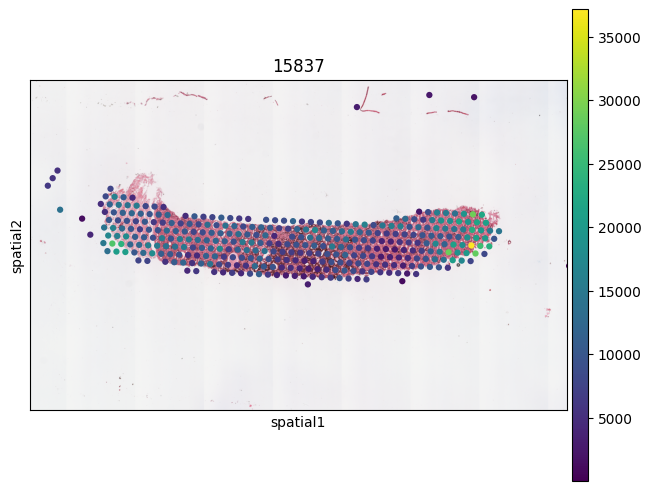

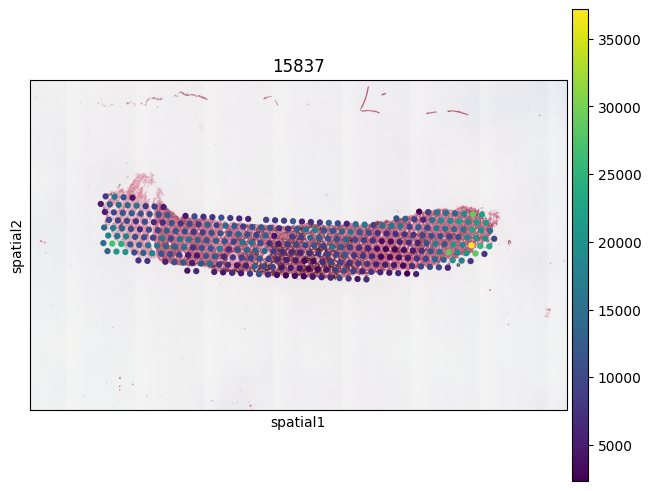

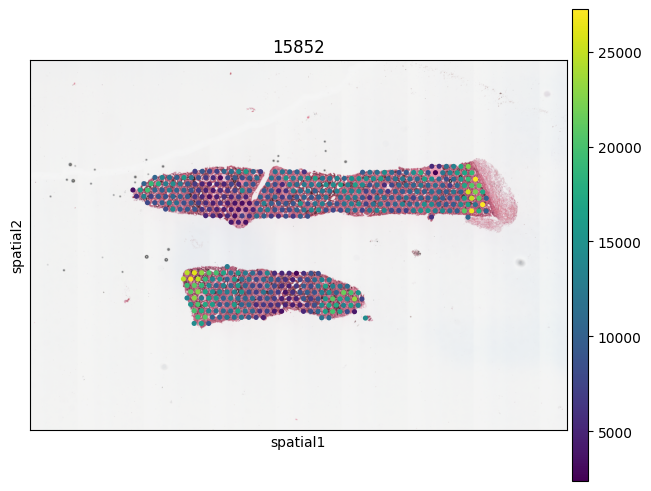

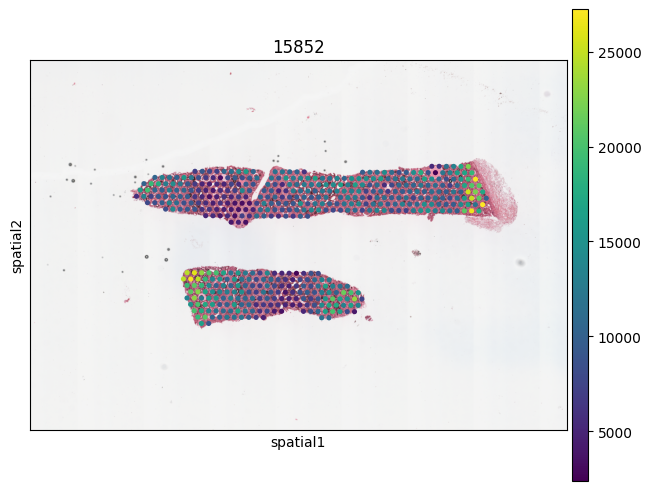

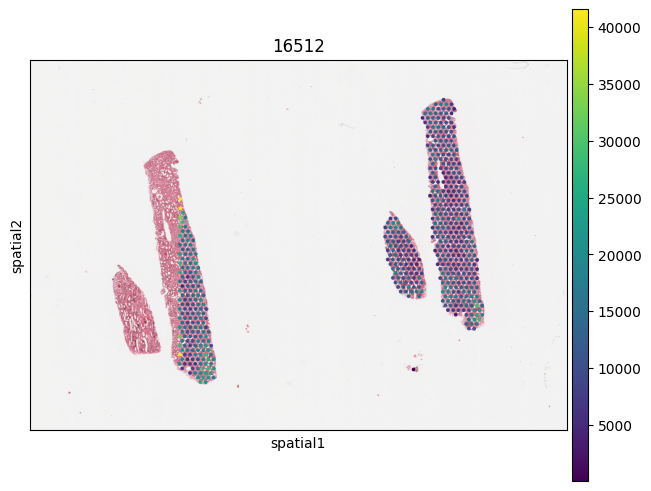

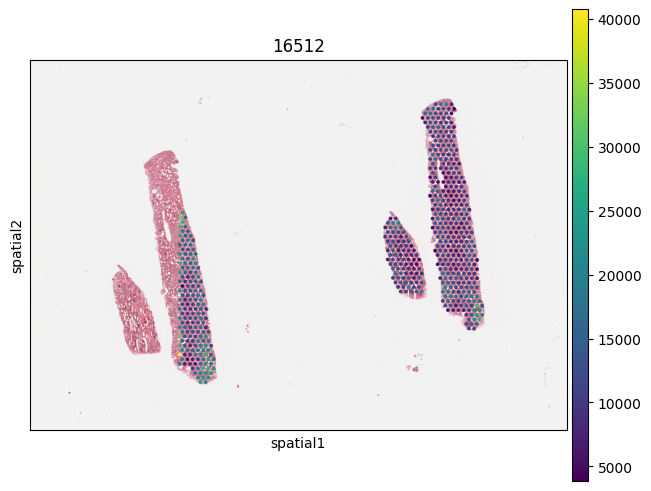

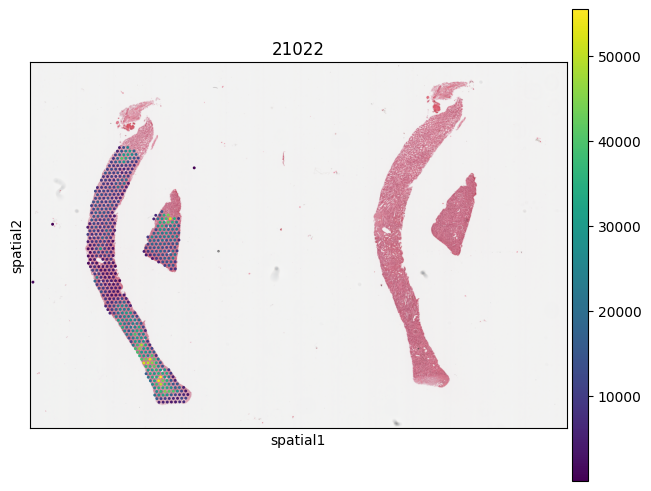

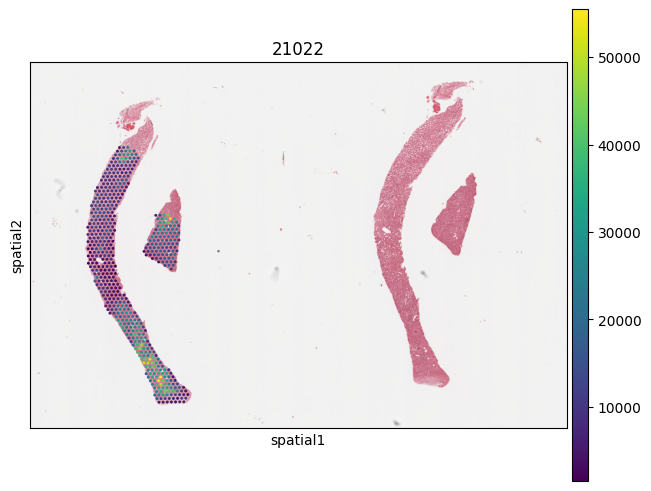

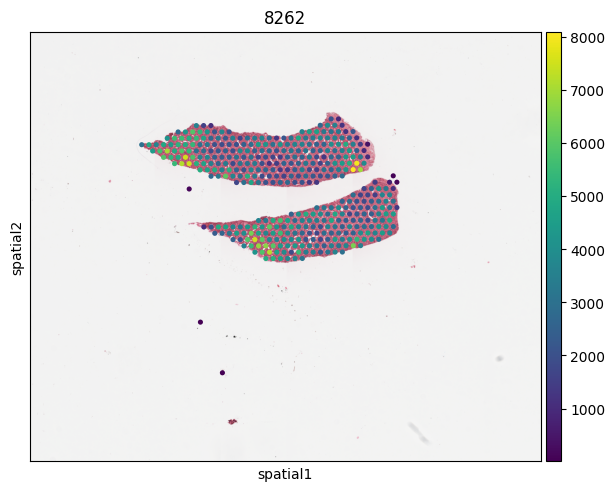

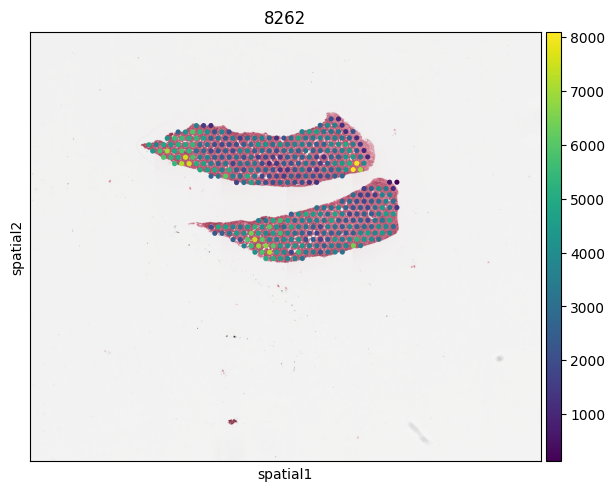

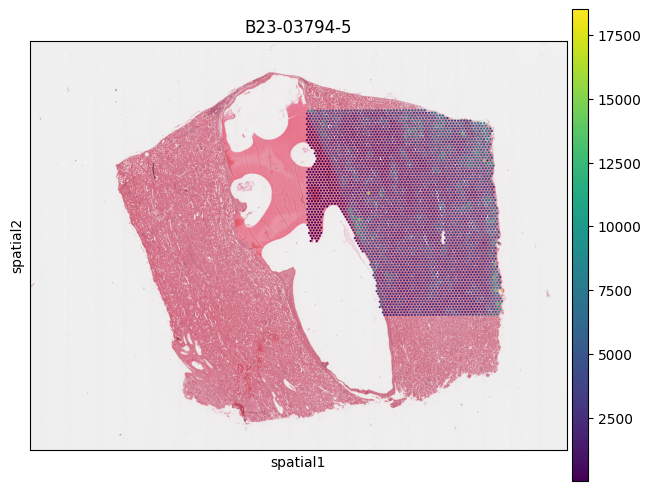

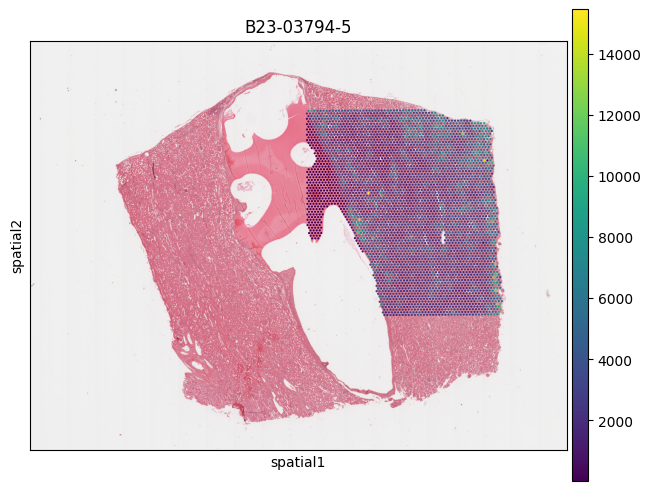

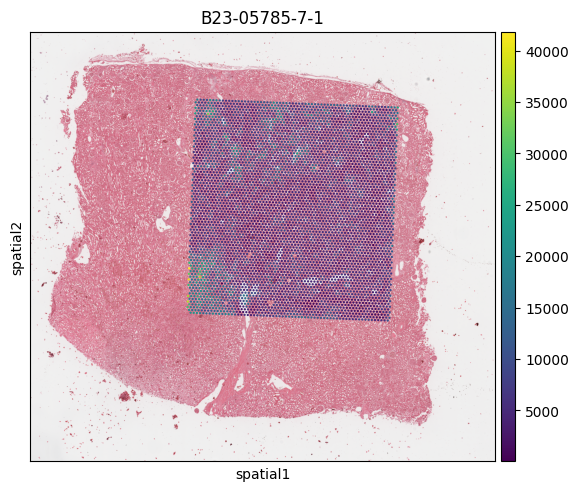

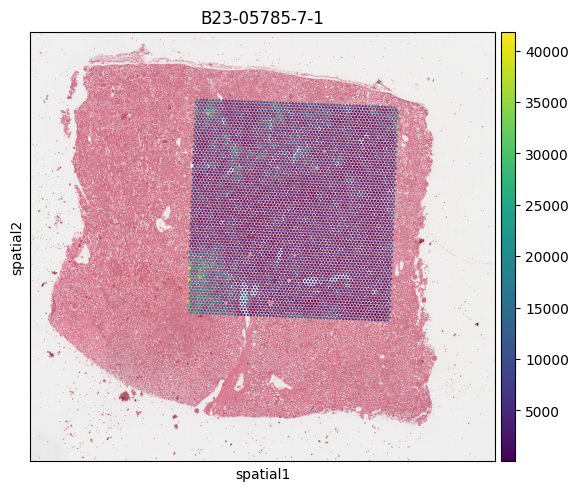

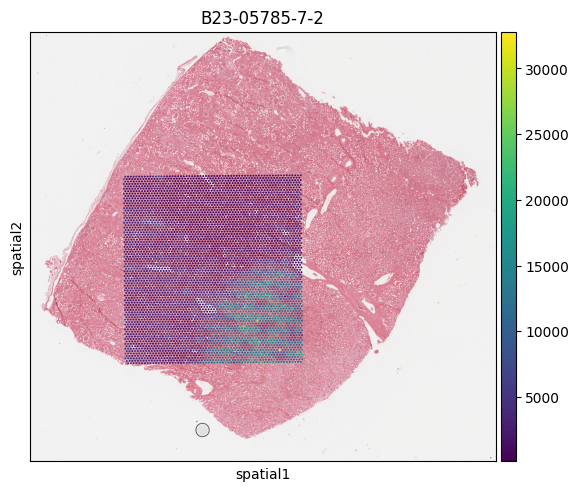

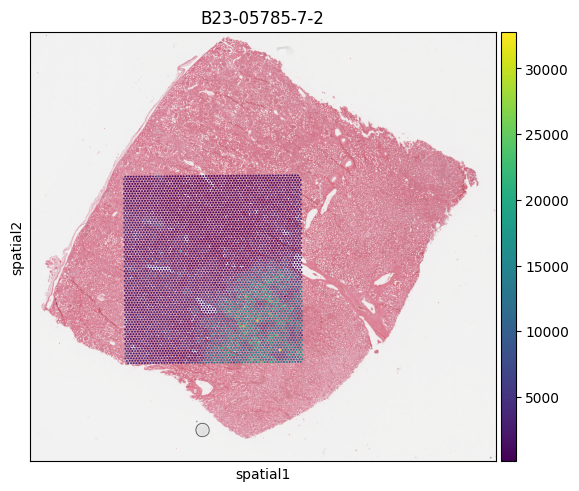

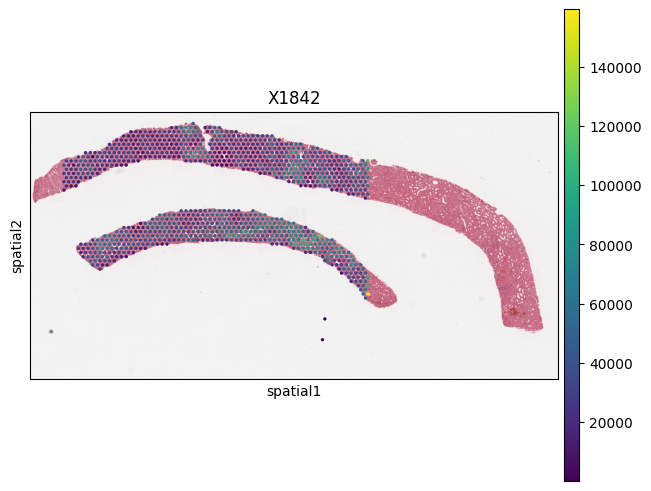

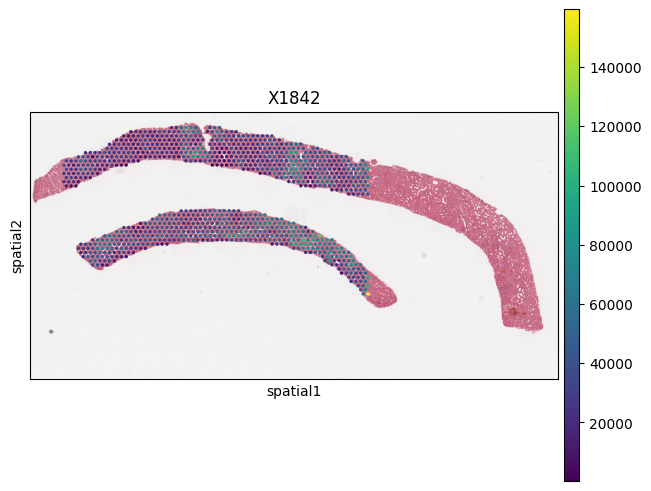

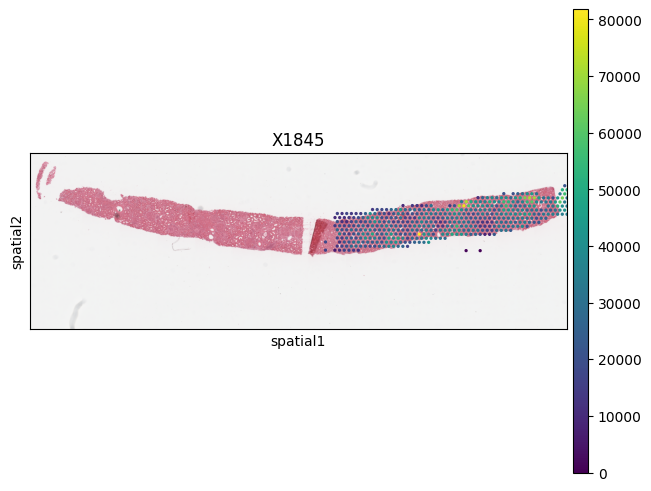

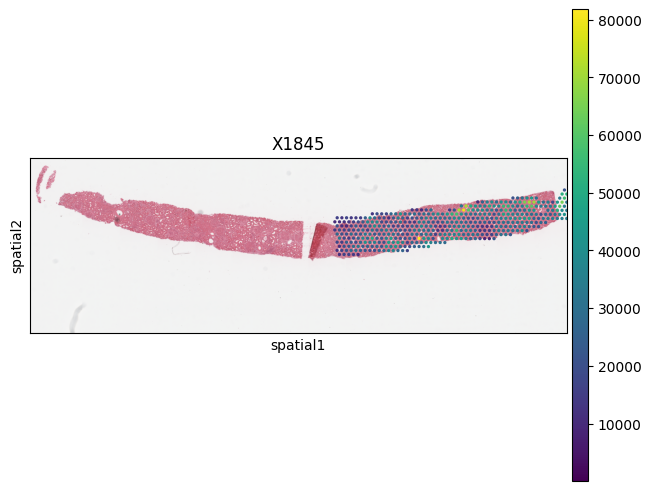

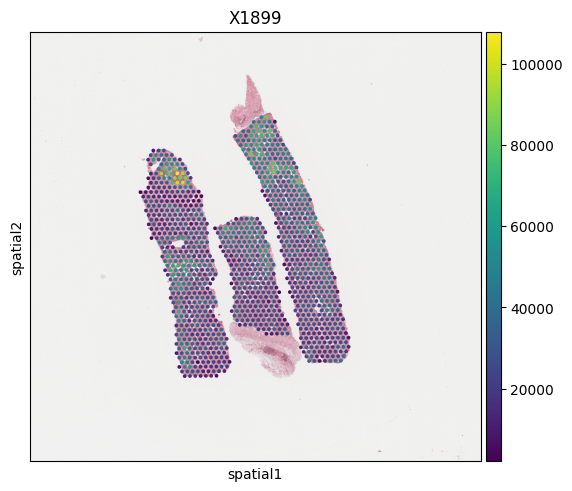

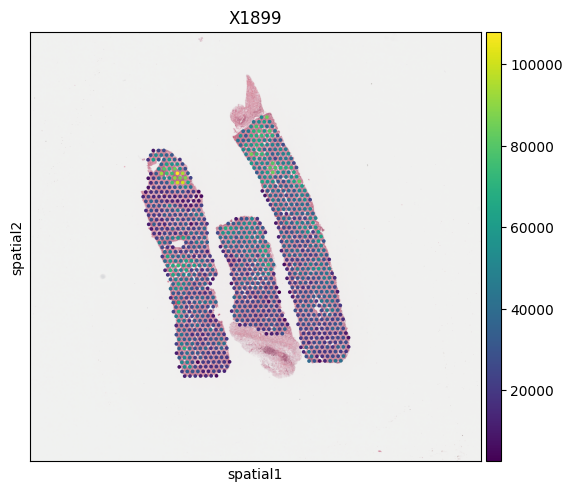

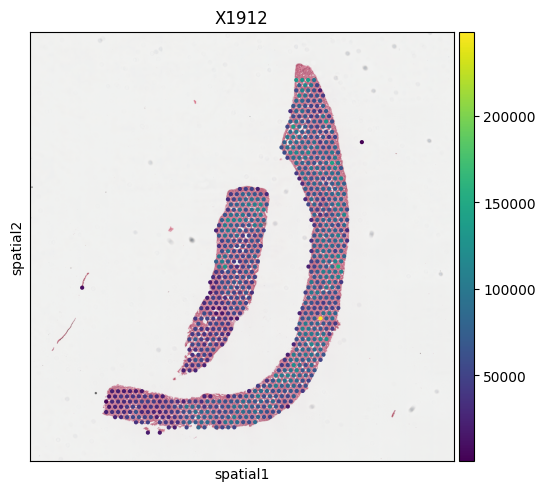

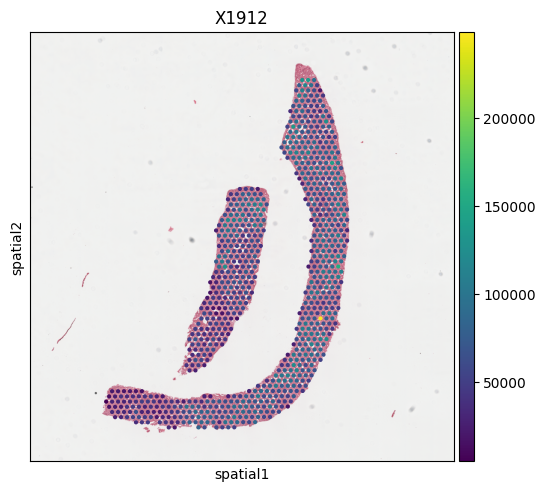

In [4]:
for sample in sample_list:
    adata = sc.read_h5ad(f"{in_dir}/{sample}.h5ad")
    
    adata = adata[adata.obs['in_tissue'] == 1, ].copy()
    
    sq.gr.spatial_neighbors(
        adata,
        coord_type="grid",
        n_neighs=6,      
    )

    adj = adata.obsp['spatial_connectivities']  # sparse matrix (n_spots x n_spots)

    # Count number of neighbors per spot
    num_neighbors = np.array(adj.sum(axis=1)).flatten()
    
    # Spots with at least 1 neighbor
    keep_mask = num_neighbors > 2

    adata_filtered = adata[keep_mask].copy()

    sq.pl.spatial_scatter(adata, color='total_counts', title=sample)
    sq.pl.spatial_scatter(adata_filtered, color='total_counts', title=sample)

    adata_filtered.write_h5ad(f'{out_dir}/{sample}.h5ad')